# Graph Convolutional Networks on Cora

Le travail de notebook s’appuie sur les travaux de Kipf & Welling (2017), *Semi-Supervised Classification with Graph Convolutional Networks* (ICLR).

On utilise le jeu de données Cora pour entraîner un MLP et un réseau convolutif sur les graphes (GCN) implémenté avec PyTorch, puis comparer ce dernier à GCNConv de PyTorch Geometric sur dix graines aléatoires.

Ensuite, on s’intéresse à la visualisation des représentations des nœuds avec t-SNE et l'étude de l’influence de la profondeur du réseau sur le phénomène de sur-lissage (over-smoothing).

In [ ]:
# %pip install torch torch_geometric scikit-learn matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv
from torch_geometric.utils import to_dense_adj

torch.set_num_threads(4)
DEVICE = torch.device("cpu")

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

## 1. Lecture des données

On normalise les caractéristiques de type sac de mots (bag-of-words) de chaque nœud avec `NormalizeFeatures`, comme dans l’article. On utilise ensuite la séparation standard des données proposée par Yang et al. (2016), avec 140 nœuds pour l’entraînement, 500 pour la validation et 1 000 pour le test.

In [ ]:
import torch_geometric.transforms as T

dataset = Planetoid(root="data/Planetoid", name="Cora", transform=T.NormalizeFeatures())
data = dataset[0].to(DEVICE)

print(data)
print(f"Nodes {data.num_nodes} | edges {data.num_edges // 2} (undirected) | "
      f"features {dataset.num_features} | classes {dataset.num_classes}")
print(f"Train {int(data.train_mask.sum())} | val {int(data.val_mask.sum())} | test {int(data.test_mask.sum())}")
print("Average degree", round(data.num_edges / data.num_nodes, 2))

Processing...
Done!


Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
Nodes 2708 | edges 5278 (undirected) | features 1433 | classes 7
Train 140 | val 500 | test 1000
Average degree 3.9


## 2. Entraînement

On reprend les mêmes paramètres que dans l’article (l’optimiseur Adam avec un taux d’apprentissage de 0,01, un weight decay de $5\cdot10^{-4}$ et un dropout de 0,5). L’entraînement dure jusqu’à 200 époques, avec un arrêt anticipé (early stopping) basé sur la perte de validation, avec une patience de 10 époques, activé après 50 époques d’échauffement afin d’éviter un arrêt trop précoce. Enfin, on évalue sur le jeu de test le modèle ayant obtenu la meilleure perte de validation.

In [6]:
def train_eval(model, data, epochs=200, lr=0.01, weight_decay=5e-4, patience=10, warmup=50):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_state, wait = float("inf"), None, 0
    for epoch in range(epochs):
        model.train(); opt.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward(); opt.step()

        model.eval()
        with torch.no_grad():
            out = model(data.x, data.edge_index)
            val_loss = F.cross_entropy(out[data.val_mask], data.y[data.val_mask]).item()
        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        elif epoch >= warmup:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(dim=1)
    acc = lambda m: (pred[m] == data.y[m]).float().mean().item()
    return {"val": acc(data.val_mask), "test": acc(data.test_mask)}

## 3. Modèle de référence : un MLP qui ignore le graphe

On classe chaque article uniquement à partir de son propre contenu textuel, sans tenir compte de ses liens avec les autres articles.

In [7]:
class MLP(nn.Module):
    def __init__(self, d_in, d_hid, d_out, dropout=0.5):
        super().__init__()
        self.lin1, self.lin2, self.dropout = nn.Linear(d_in, d_hid), nn.Linear(d_hid, d_out), dropout

    def forward(self, x, edge_index=None):
        x = F.dropout(x, self.dropout, self.training)
        x = F.relu(self.lin1(x))
        x = F.dropout(x, self.dropout, self.training)
        return self.lin2(x)

set_seed(0)
print("MLP", train_eval(MLP(dataset.num_features, 16, dataset.num_classes), data))

MLP {'val': 0.5920000076293945, 'test': 0.5770000219345093}


## 4. Implémentation d’un GCN à partir de zéro

On calcule la matrice d’adjacence normalisée $\hat A = \tilde D^{-1/2}\tilde A\tilde D^{-1/2}$, où $\tilde A = A + I$ ajoute des boucles sur soi-même (self-loops) et $\tilde D$ est la matrice des degrés associée à $\tilde A$. Le modèle comporte deux couches :
$Z = \mathrm{softmax}\big(\hat A\,\mathrm{ReLU}(\hat A X W^{(0)})\,W^{(1)}\big)$

La multiplication par $\hat A$ remplace la représentation de chaque nœud par une moyenne pondérée de sa propre représentation et de celles de ses voisins. Cette opération constitue une approximation du premier ordre d’une convolution spectrale sur un graphe. On calcule $\hat A$ une seule fois et on la stocke sous forme de matrice creuse (sparse matrix), ce qui permet d’obtenir un coût de calcul linéaire par rapport au nombre d’arêtes.

In [8]:
def normalized_adjacency(edge_index, n):
    A = to_dense_adj(edge_index, max_num_nodes=n)[0]
    A_tilde = A + torch.eye(n)
    d_inv_sqrt = A_tilde.sum(dim=1).pow(-0.5)
    A_hat = d_inv_sqrt[:, None] * A_tilde * d_inv_sqrt[None, :]
    return A_hat.to_sparse()

A_hat = normalized_adjacency(data.edge_index, data.num_nodes)

# Sanity check, the largest eigenvalue of A_hat is 1 (which keeps repeated propagation stable)
eigmax = torch.linalg.eigvalsh(A_hat.to_dense()).max().item()
print(f"A_hat {tuple(A_hat.shape)}, {A_hat._nnz()} non-zeros, largest eigenvalue {eigmax:.4f}")


class GCNLayer(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W = nn.Linear(d_in, d_out, bias=False)
        nn.init.xavier_uniform_(self.W.weight)  # Glorot init, as in the paper

    def forward(self, H, A_hat):
        return torch.sparse.mm(A_hat, self.W(H))


class GCNScratch(nn.Module):
    def __init__(self, d_in, d_hid, d_out, A_hat, dropout=0.5):
        super().__init__()
        self.l1, self.l2, self.A_hat, self.dropout = GCNLayer(d_in, d_hid), GCNLayer(d_hid, d_out), A_hat, dropout

    def embed(self, x):
        x = F.dropout(x, self.dropout, self.training)
        return F.relu(self.l1(x, self.A_hat))

    def forward(self, x, edge_index=None):
        h = F.dropout(self.embed(x), self.dropout, self.training)
        return self.l2(h, self.A_hat)  # softmax is inside the cross-entropy loss

set_seed(0)
print("GCN (scratch)", train_eval(GCNScratch(dataset.num_features, 16, dataset.num_classes, A_hat), data))

A_hat (2708, 2708), 13264 non-zeros, largest eigenvalue 1.0000
GCN (scratch) {'val': 0.7820000052452087, 'test': 0.8259999752044678}


## 5. Même modèle avec PyTorch Geometric et robustesse sur 10 graines aléatoires

On utilise `GCNConv`, qui applique la même règle de propagation à l’aide du mécanisme de message passing. Sur cette séparation des données, l’article rapporte une précision de 81,5 %.

In [9]:
class GCN(nn.Module):
    def __init__(self, d_in, d_hid, d_out, n_layers=2, dropout=0.5):
        super().__init__()
        dims = [d_in] + [d_hid] * (n_layers - 1) + [d_out]
        self.convs = nn.ModuleList(GCNConv(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.dropout = dropout

    def forward(self, x, edge_index):
        for i, conv in enumerate(self.convs):
            x = F.dropout(x, self.dropout, self.training)
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.relu(x)
        return x

SEEDS = range(10)
rows = []
for seed in SEEDS:
    for name, make in [("MLP", lambda: MLP(dataset.num_features, 16, dataset.num_classes)),
                       ("GCN scratch", lambda: GCNScratch(dataset.num_features, 16, dataset.num_classes, A_hat)),
                       ("GCN (PyG)", lambda: GCN(dataset.num_features, 16, dataset.num_classes))]:
        set_seed(seed)
        rows.append({"model": name, "seed": seed, **train_eval(make(), data)})

res = pd.DataFrame(rows)
summary = (res.groupby("model")[["val", "test"]].agg(["mean", "std"]) * 100).round(1)
summary

val       test     
             mean  std  mean  std
model                            
GCN (PyG)    79.4  1.2  82.3  0.3
GCN scratch  78.6  0.6  81.7  0.8
MLP          58.6  1.4  57.9  1.6

## 6. Visualisation des représentations apprises par le GCN avec t-SNE

On projette en deux dimensions les représentations internes de 16 dimensions des 2 708 nœuds. Bien que seuls 140 nœuds soient étiquetés, on observe des groupes bien distincts selon les classes, car le graphe permet de propager l’information des nœuds étiquetés vers leurs voisins.

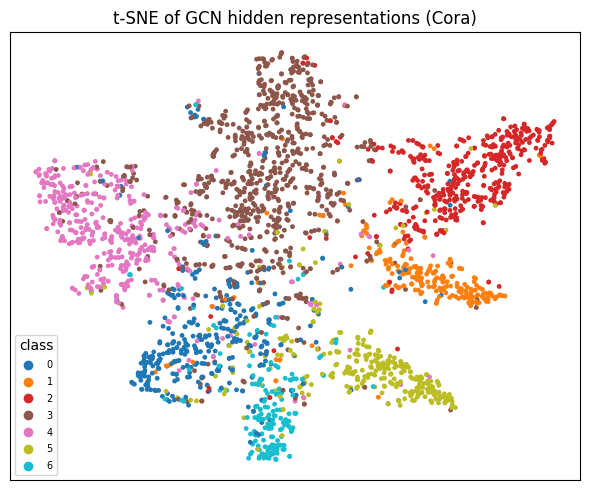

In [10]:
from sklearn.manifold import TSNE

set_seed(0)
model = GCNScratch(dataset.num_features, 16, dataset.num_classes, A_hat)
train_eval(model, data)
with torch.no_grad():
    H = model.embed(data.x).numpy()
Z = TSNE(n_components=2, init="pca", random_state=0).fit_transform(H)

plt.figure(figsize=(6, 5))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=data.y.numpy(), cmap="tab10", s=6)
plt.legend(*sc.legend_elements(), title="class", fontsize=7, loc="best")
plt.title("t-SNE of GCN hidden representations (Cora)")
plt.xticks([]); plt.yticks([]); plt.tight_layout(); plt.show()

## 7. Influence de la profondeur du réseau et phénomène de sur-lissage

À chaque couche du GCN, les nœuds agrègent l’information de leurs voisins à une distance supplémentaire. Lorsque le nombre de couches augmente, les représentations des nœuds d’une même région connexe deviennent progressivement similaires, rendant les classes difficiles à distinguer.

On mesure la précision sur le jeu de test pour des réseaux comportant de 1 à 16 couches, ainsi que la similarité cosinus moyenne entre les représentations finales des nœuds, qui tend à augmenter lorsqu’elles deviennent similaires. La baisse de précision peut également s’expliquer par la difficulté à entraîner des réseaux profonds, notamment en l’absence de connexions résiduelles et de normalisation. Les deux effets peuvent donc se combiner.

         test  cosine
layers               
1       76.98   0.107
2       82.22   0.150
3       80.20   0.141
4       73.56   0.131
6       35.74   0.277
8       24.78   0.285
16      16.72   0.576


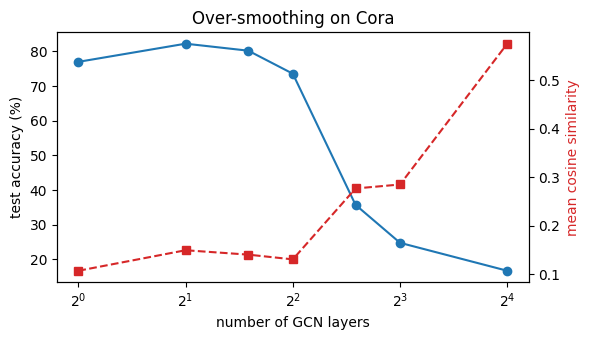

In [11]:
def mean_cosine(X, n=500, seed=0):
    idx = np.random.default_rng(seed).choice(X.shape[0], n, replace=False)
    Xn = F.normalize(X[idx], dim=1)
    S = Xn @ Xn.T
    return ((S.sum() - n) / (n * (n - 1))).item()

rows = []
for L in [1, 2, 3, 4, 6, 8, 16]:
    for seed in range(5):
        set_seed(seed)
        m = GCN(dataset.num_features, 16, dataset.num_classes, n_layers=L)
        r = train_eval(m, data)
        with torch.no_grad():
            out = m(data.x, data.edge_index)
        rows.append({"layers": L, "seed": seed, "test": r["test"], "cosine": mean_cosine(out)})

depth = pd.DataFrame(rows).groupby("layers")[["test", "cosine"]].mean()
depth["test"] *= 100
print(depth.round(3))

fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot(depth.index, depth["test"], "o-", label="test accuracy (%)")
ax1.set_xlabel("number of GCN layers"); ax1.set_ylabel("test accuracy (%)"); ax1.set_xscale("log", base=2)
ax2 = ax1.twinx()
ax2.plot(depth.index, depth["cosine"], "s--", c="tab:red", label="mean cosine similarity")
ax2.set_ylabel("mean cosine similarity", color="tab:red")
ax1.set_title("Over-smoothing on Cora"); fig.tight_layout(); plt.show()

## 8. Bilan

- Un GCN à deux couches exploite les liens de citation pour atteindre environ 80 % de précision avec seulement 140 étiquettes, dépassant largement le MLP qui traite chaque article individuellement. Notre implémentation reproduit les résultats de PyTorch Geometric.
- Les représentations apprises se regroupent par classe, alors que la grande majorité des nœuds ne sont pas étiquetés.
- Augmenter la profondeur du GCN n’améliore pas les performances : la précision atteint son maximum à deux couches, puis chute au-delà de quatre couches. À 16 couches, les représentations des nœuds deviennent beaucoup plus similaires. Ces observations sont cohérentes avec le phénomène de sur-lissage (*over-smoothing*), même si la similarité cosinus n’augmente pas de façon monotone et que les difficultés d’optimisation jouent également un rôle.

**Limites.** Cette étude porte sur un seul petit graphe homophile, dans lequel les articles liés partagent généralement un même thème, et se limite à la classification de nœuds avec une séparation standard des données. Les graphes hétérophiles, les tâches de classification de graphes entiers et les graphes dynamiques peuvent présenter des comportements différents.

In [12]:
final = {
    "MLP test acc (%)": res[res.model == "MLP"].test.mean() * 100,
    "GCN scratch test acc (%)": res[res.model == "GCN scratch"].test.mean() * 100,
    "GCN PyG test acc (%)": res[res.model == "GCN (PyG)"].test.mean() * 100,
    "GCN PyG std (%)": res[res.model == "GCN (PyG)"].test.std() * 100,
    "Best depth": int(depth["test"].idxmax()),
    "16-layer GCN test acc (%)": depth.loc[16, "test"],
}
pd.Series(final).round(1)

MLP test acc (%)             57.9
GCN scratch test acc (%)     81.7
GCN PyG test acc (%)         82.3
GCN PyG std (%)               0.3
Best depth                    2.0
16-layer GCN test acc (%)    16.7
dtype: float64

## References

* Kipf, Welling (2017). Semi-supervised classification with graph convolutional networks. *ICLR*. arXiv:1609.02907.
* Yang, Cohen, Salakhutdinov (2016). Revisiting semi-supervised learning with graph embeddings. *ICML*.
* Giraldo, Skianis, Bouwmans, Malliaros (2023). Understanding the relationship between over-smoothing and over-squashing in deep graph neural networks. *CIKM*.
* Fey, Lenssen (2019). Fast graph representation learning with PyTorch Geometric. *ICLR Workshop*.